In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re, numpy as np
data = pd.read_csv("cleaned_a.csv")
data

,review_id,app_name,domain,rating,date,review_text,review_type,normalized_text,is_franco
0,2e6046b5-4407-45ad-8487-c1ef349bae02,Amazon,E-commerce,5,2026-09-29,l love shopping here Ma shaa Allah,Positive,l love shopping here ma shaa allah,False
1,fb178bf4-ef23-4227-980d-284a8905a57a,Amazon,E-commerce,5,2026-09-29,الله واكبر لاله الا الله والله واكبر سبحان الل...,Positive,الله واكبر لاله الا الله والله واكبر سبحان الل...,False
2,2856ab4b-4270-486b-ab56-aeb9116cf879,Amazon,E-commerce,1,2026-09-29,التطبيق فية لاج الصور كلها سودة,Negative,التطبيق فيه لاج الصور كلها سوده,False
3,cc842fc5-c895-4246-af12-df33a1e8f087,Amazon,E-commerce,5,2026-09-29,gooood ?,Positive,good,False
4,c7f05214-0917-4e24-b6f1-1d97d9effef7,Amazon,E-commerce,4,2026-09-29,"كپعا دك.ك،،،،،،،،,,،,،،،،،،،،،،،،،،,,74%,چ,ؤلي...",Positive,كبعا دك ك 74% ج ؤلئر ي كد في دن د في ففءفلف دد...,False
...,...,...,...,...,...,...,...,...,...
63204,2868551f-c0ff-4847-a31f-d3c8ad210466,WE,Telecom,2,2026-08-24,دايما لازم اعمل تسجيل تانى و لما النت يخلص مش ...,Negative,دايما لازم اعمل تسجيل تاني ولما النت يخلص مش ب...,False
63205,b56f4164-a08d-4d51-9763-71431f5712d9,WE,Telecom,5,2026-08-24,جميل جدا,Positive,جميل جدا,False
63206,d7392087-44c6-42a9-aa5b-f32adc88a29d,WE,Telecom,1,2026-08-24,واحد خدمات سيئه وتعبانه عميل واحد في الفرع وبا...,Negative,واحد خدمات سئه وتعبانه عميل واحد في الفرع وباق...,False
63207,ad8578c8-a792-45e3-8086-f68f20f19ae2,WE,Telecom,1,2026-08-24,غير جيده,Negative,غير جيده,False


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 63209 entries, 0 to 63208
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   review_id        63209 non-null  str  
 1   app_name         63209 non-null  str  
 2   domain           63209 non-null  str  
 3   rating           63209 non-null  int64
 4   date             63209 non-null  str  
 5   review_text      63208 non-null  str  
 6   review_type      63209 non-null  str  
 7   normalized_text  63204 non-null  str  
 8   is_franco        63209 non-null  bool 
dtypes: bool(1), int64(1), str(7)
memory usage: 3.9 MB


In [3]:
data["date"] = pd.to_datetime(data["date"])

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 63209 entries, 0 to 63208
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   review_id        63209 non-null  str           
 1   app_name         63209 non-null  str           
 2   domain           63209 non-null  str           
 3   rating           63209 non-null  int64         
 4   date             63209 non-null  datetime64[us]
 5   review_text      63208 non-null  str           
 6   review_type      63209 non-null  str           
 7   normalized_text  63204 non-null  str           
 8   is_franco        63209 non-null  bool          
dtypes: bool(1), datetime64[us](1), int64(1), str(6)
memory usage: 3.9 MB


In [5]:
data[data['review_text'].isnull()]

,review_id,app_name,domain,rating,date,review_text,review_type,normalized_text,is_franco
27029,4e0b44e0-c9ce-4524-b430-aa6421fe6d5d,Fawry,Payments,5,2025-11-17,NaN,Positive,NaN,False


In [6]:
data[data['normalized_text'].isnull()]

,review_id,app_name,domain,rating,date,review_text,review_type,normalized_text,is_franco
10073,987355e3-e1dc-4577-9e8c-c8d27b5a54bb,Careem,Transport Services,5,2025-11-04,(^ー^),Positive,NaN,False
14900,dc06e889-4887-4978-a83a-baa2558ecf52,CIB,Banking,5,2025-01-12,Супер,Positive,NaN,False
27029,4e0b44e0-c9ce-4524-b430-aa6421fe6d5d,Fawry,Payments,5,2025-11-17,NaN,Positive,NaN,False
36366,6d695bb6-82e0-40a3-8f97-8d092aa581f2,Jumia,E-commerce,1,2025-09-06,. .,Negative,NaN,False
52753,c28eecde-40c7-4b42-9424-d4e44dd84089,Uber,Transport Services,5,2026-08-27,很好！,Positive,NaN,False


In [7]:
data.describe()

,rating,date
count,63209.000000,63209
mean,3.524546,2026-04-11 20:56:20.100935
min,1.000000,2023-07-28 00:00:00
25%,1.000000,2026-02-18 00:00:00
50%,5.000000,2026-06-27 00:00:00
75%,5.000000,2026-09-01 00:00:00
max,5.000000,2026-09-29 00:00:00
std,1.850268,NaN


In [8]:
data["review_id"].duplicated().sum()

np.int64(0)

In [9]:
for column in ["app_name", "domain", "review_type"]:
    print(data[column].value_counts(), "\n")  

app_name
Amazon            4000
Banque Misr       4000
Careem            4000
DiDi              4000
Etisalat Cash     4000
Fawry             4000
inDrive           4000
Instapay          4000
Jumia             4000
NBE               4000
Noon              4000
Orange Egypt      4000
Uber              4000
Vodafone Egypt    4000
WE                4000
CIB               3209
Name: count, dtype: int64 

domain
Transport Services    16000
E-commerce            12000
Payments              12000
Telecom               12000
Banking               11209
Name: count, dtype: int64 

review_type
Positive    39162
Negative    22209
Neutral      1838
Name: count, dtype: int64 



In [10]:
data["is_franco"].value_counts()

is_franco
False    63199
True        10
Name: count, dtype: int64

In [11]:
data.loc[data["is_franco"]==True]

,review_id,app_name,domain,rating,date,review_text,review_type,normalized_text,is_franco
1357,603397fc-fdd9-4aab-9b49-e65173805b7b,Amazon,E-commerce,2,2026-06-26,"Amazon global bir uygulama olduğundan, kullanı...",Negative,amazon global bir uygulama oldugundan kullanic...,True
14708,f2a4d30c-895e-44ba-a04a-0dc2fae504d8,CIB,Banking,5,2025-01-21,Gamed gedan,Positive,gamed gedan,True
28555,30ac6e8d-5e5a-4ea2-915f-4b827390d673,inDrive,Transport Services,5,2026-09-06,taxs al3sama,Positive,taxs al3sama,True
29718,80d00766-4ef0-410e-bcdc-e247aabd2c7f,inDrive,Transport Services,5,2026-08-14,a7sn tatbi9,Positive,a7sn tatbi9,True
30184,b3dea1e8-2406-4f76-9cf4-5603c8664e39,inDrive,Transport Services,5,2026-08-05,sara7a ttbi9 dyl indreve chi 7ja li nf3atna o ...,Positive,sara7a ttbi9 dyl indreve chi 7ja li nf3atna o ...,True
36540,b974b7b0-0ffb-4f95-a676-743095b73ec5,Jumia,E-commerce,1,2025-07-13,m5damt liya knbri nsri mki9blot liya,Negative,m5damt liya knbri nsri mki9blot liya,True
38278,01f6e84d-3a9d-4d6b-96b3-1fa927625098,Jumia,E-commerce,1,2024-02-10,9and n njY,Negative,9and n njy,True
38611,5e0b491c-69ad-42ad-a60f-b3d70abe859a,Jumia,E-commerce,2,2023-11-26,Ana kanbrit nakhod man3ankom walking makaynach...,Negative,ana kanbrit nakhod man3ankom walking makaynach...,True
56015,c94f090b-4988-4f4a-9edd-c70269304d1a,Vodafone Egypt,Telecom,5,2026-09-16,VF və digər sahələrdə olduğu halda bu t və k b...,Positive,vf va digar sahalarda oldugu halda bu t va k b...,True
60198,1451df7a-58ae-424f-b500-1663f5ac6da1,WE,Telecom,5,2026-09-18,Ibrahim Abu Al-Majd Al-Sayyid Hassan,Positive,ibrahim abu al majd al sayyid hassan,True


In [12]:
data = data.dropna(subset=["review_text", "normalized_text"]).copy() 

In [13]:
print(data.isnull().sum())
print("\nNew Dataset Shape:", data.shape)

review_id          0
app_name           0
domain             0
rating             0
date               0
review_text        0
review_type        0
normalized_text    0
is_franco          0
dtype: int64

New Dataset Shape: (63204, 9)


In [14]:
print(pd.crosstab(data["rating"], data["review_type"])) 

review_type  Negative  Neutral  Positive
rating                                  
1               20633        0         0
2                1575        0         0
3                   0     1838         0
4                   0        0      2325
5                   0        0     36833


In [15]:
data.isnull().sum()

review_id          0
app_name           0
domain             0
rating             0
date               0
review_text        0
review_type        0
normalized_text    0
is_franco          0
dtype: int64

In [16]:
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate IDs:", data["review_id"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


In [17]:
data["rating"].value_counts().sort_index()

rating
1    20633
2     1575
3     1838
4     2325
5    36833
Name: count, dtype: int64

In [18]:
print("Unique ratings:", sorted(data["rating"].unique()))
print("\nRating data type:", data["rating"].dtype)
print("\nZero ratings:", (data["rating"] == 0).sum())
print("Missing ratings:", data["rating"].isna().sum())

Unique ratings: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Rating data type: int64

Zero ratings: 0
Missing ratings: 0


In [ ]:
def script(t):
    ar = len(re.findall(r"[\u0600-\u06FF]", t))
    la = len(re.findall(r"[A-Za-z]", t))
    if ar == 0 and la == 0: return "other/none"
    if ar >= la: return "arabic"
    return "latin"
data["script"] = data["normalized_text"].apply(script)
print(data["script"].value_counts())
print(data.groupby("script")["rating"].mean().round(2))

print(data.loc[data["is_franco"], ["app_name", "review_text"]])

script
arabic        60456
latin          1798
other/none      950
Name: count, dtype: int64
script
arabic        3.48
latin         4.34
other/none    4.59
Name: rating, dtype: float64
             app_name                                        review_text
1357           Amazon  Amazon global bir uygulama olduğundan, kullanı...
14708             CIB                                        Gamed gedan
28555         inDrive                                       taxs al3sama
29718         inDrive                                        a7sn tatbi9
30184         inDrive  sara7a ttbi9 dyl indreve chi 7ja li nf3atna o ...
36540           Jumia               m5damt liya knbri nsri mki9blot liya
38278           Jumia                                         9and n njY
38611           Jumia  Ana kanbrit nakhod man3ankom walking makaynach...
56015  Vodafone Egypt  VF və digər sahələrdə olduğu halda bu t və k b...
60198              WE               Ibrahim Abu Al-Majd Al-Sayyid Hassan


In [20]:
def script(t):
    ar = len(re.findall(r"[\u0600-\u06FF]", t))
    la = len(re.findall(r"[A-Za-z]", t))
    if ar == 0 and la == 0: return "other/none"
    if ar >= la: return "arabic"
    return "latin"
data["script"] = data["normalized_text"].apply(script)
print(data["script"].value_counts())
print(data.groupby("script")["rating"].mean().round(2))


print(data.loc[data["is_franco"], ["app_name", "review_text"]])

script
arabic        60456
latin          1798
other/none      950
Name: count, dtype: int64
script
arabic        3.48
latin         4.34
other/none    4.59
Name: rating, dtype: float64
             app_name                                        review_text
1357           Amazon  Amazon global bir uygulama olduğundan, kullanı...
14708             CIB                                        Gamed gedan
28555         inDrive                                       taxs al3sama
29718         inDrive                                        a7sn tatbi9
30184         inDrive  sara7a ttbi9 dyl indreve chi 7ja li nf3atna o ...
36540           Jumia               m5damt liya knbri nsri mki9blot liya
38278           Jumia                                         9and n njY
38611           Jumia  Ana kanbrit nakhod man3ankom walking makaynach...
56015  Vodafone Egypt  VF və digər sahələrdə olduğu halda bu t və k b...
60198              WE               Ibrahim Abu Al-Majd Al-Sayyid Hassan


In [ ]:
FRANCO_WORDS = set("""momtaz mumtaz mmtaz mamtaz tmam tamam taman tamaam gamil gamila gamilah gamel jamil jamiil jamiiil jameel
gamed gamda gedan gdan gedn tohfa tohfah rawa3 raw3a rwa3 khales khalis kwayes kowayes kwayis helw helwa hilw zeft zift 7elw
sa7 sa7i7 ahsan a7sn ahssn afdal shokran shukran chokran choukran mashkour mashkoor barnamg bernameg tatbik tatbi9 tatbeek tbik
khidma khedma 5edma m5damt mesh msh mish moshkela moshkila mshkla mafesh mafish bayz bayez zbala keda kda deh dyal diyal kifach
wach bzaf bzzaf wakha safi mzyan mzian zwin machi 7ja 3ashan 3shan 3ala bgd awy awi gdn""".split())

def franco(t):
    if re.search(r"[\u0600-\u06FF]", t):
        return False
    toks = re.findall(r"[a-z0-9']+", t)
    if any(w in FRANCO_WORDS for w in toks):
        return True
    return any(re.search(r"[a-z][235679]|[235679][a-z]", w)
               and not re.fullmatch(r"\d+[a-z]{1,2}|[a-z]\d", w) for w in toks)

data["is_franco_new"] = data["normalized_text"].apply(franco)
print(data["is_franco_new"].value_counts())
print(data.loc[data["is_franco_new"], ["app_name", "rating", "review_text"]].to_string())

is_franco_new
False    63174
True        30
Name: count, dtype: int64
             app_name  rating                                                                                                                                                                                                                                                                                                                                                                                                                                                                        review_text
603            Amazon       1  Subject: Complaint - Order Not Delivered + Request Refund Hello Amazon Customer Service, I am writing to file a formal complaint regarding my order that has NOT been delivered. Order Details: - Shipping Address: Akot mading dut, 237ladysmithdr , St. John's, NL - Items: Priorin (2 bottles) and Hair Growth Vitamins (3 packs) - Order Date: August 12, 2026 - Estimated Delivery: July 26 - July 31, 2026 T

In [22]:
data["char_len"] = data["normalized_text"].str.len()
data["word_len"] = data["normalized_text"].str.split().str.len()
print(data[["char_len", "word_len"]].describe().round(1))

q1, q3 = data["word_len"].quantile([.25, .75]); iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("Long-review outliers (> %.0f words): %d" % (upper, (data["word_len"] > upper).sum()))
print("Very short (<=1 word):", (data["word_len"] <= 1).sum())

       char_len  word_len
count   63204.0   63204.0
mean       41.1       7.9
std        66.4      12.4
min         1.0       1.0
25%         5.0       1.0
50%        14.0       3.0
75%        47.0       9.0
max       522.0     108.0
Long-review outliers (> 21 words): 6038
Very short (<=1 word): 18591


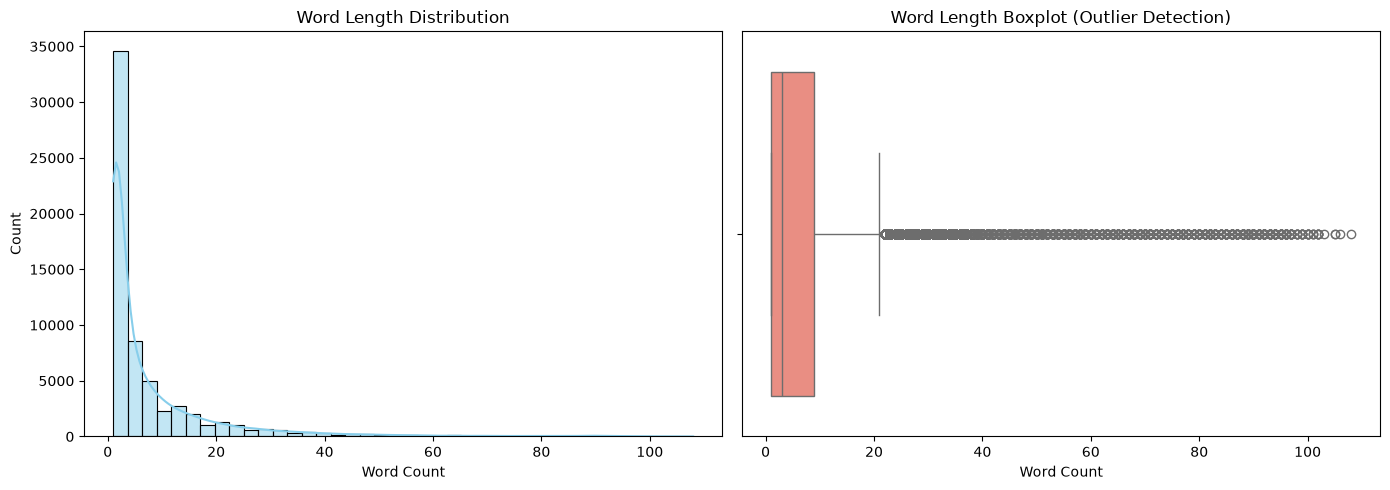

=== Text Length Statistics ===
           char_len      word_len
count  63204.000000  63204.000000
mean      41.106860      7.921556
std       66.427602     12.390603
min        1.000000      1.000000
25%        5.000000      1.000000
50%       14.000000      3.000000
75%       47.000000      9.000000
max      522.000000    108.000000


In [23]:

data['char_len'] = data['normalized_text'].str.len()
data['word_len'] = data['normalized_text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data['word_len'], bins=40, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Word Length Distribution')
axes[0].set_xlabel('Word Count')

sns.boxplot(x=data['word_len'], ax=axes[1], color='salmon')
axes[1].set_title('Word Length Boxplot (Outlier Detection)')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

print("=== Text Length Statistics ===")
print(data[['char_len', 'word_len']].describe())

In [24]:
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.to_period("M").astype(str)
print("Range:", data["date"].min().date(), "->", data["date"].max().date())
print("Future dates:", (data["date"] > pd.Timestamp.today()).sum())
print(data["year"].value_counts().sort_index())
print(data.groupby("app_name")["date"].agg(["min", "max"]))

Range: 2023-07-28 -> 2026-09-29
Future dates: 0
year
2023      757
2024     2431
2025     7859
2026    52157
Name: count, dtype: int64
                      min        max
app_name                            
Amazon         2025-12-03 2026-09-29
Banque Misr    2026-01-10 2026-09-29
CIB            2024-11-06 2026-09-29
Careem         2025-06-05 2026-09-29
DiDi           2026-03-22 2026-09-29
Etisalat Cash  2025-10-31 2026-09-29
Fawry          2025-11-08 2026-09-29
Instapay       2026-03-07 2026-09-29
Jumia          2023-07-28 2026-09-28
NBE            2024-04-24 2026-09-29
Noon           2026-01-18 2026-09-29
Orange Egypt   2026-08-31 2026-09-29
Uber           2026-07-13 2026-09-29
Vodafone Egypt 2026-07-29 2026-09-29
WE             2026-08-24 2026-09-29
inDrive        2026-07-15 2026-09-29


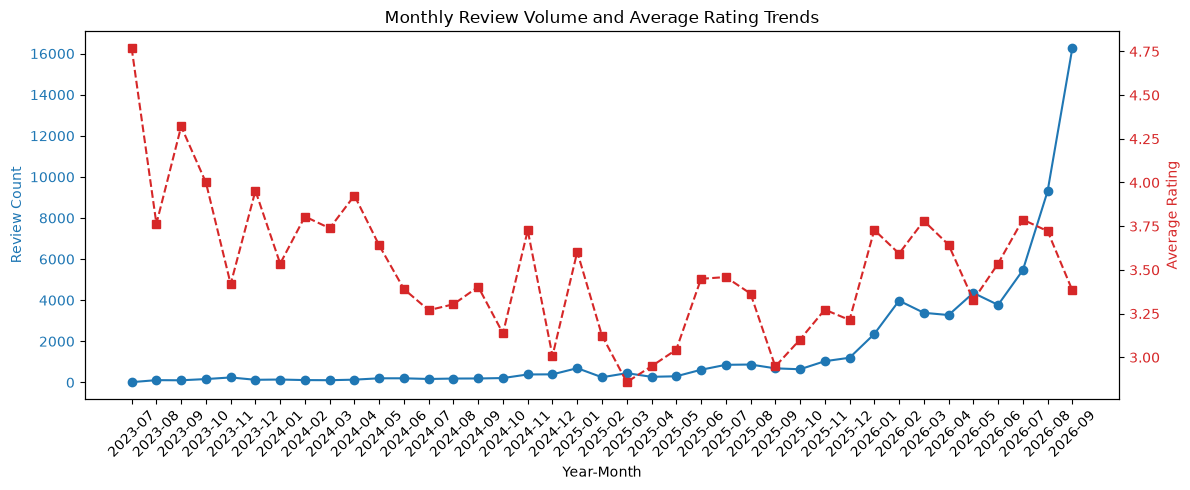

In [25]:
data['year_month'] = data['date'].dt.to_period('M')
monthly_trends = data.groupby('year_month').agg(
    review_count=('review_id', 'count'),
    avg_rating=('rating', 'mean')
).reset_index()

monthly_trends['year_month'] = monthly_trends['year_month'].astype(str)

fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Year-Month')
ax1.set_ylabel('Review Count', color=color)
ax1.plot(monthly_trends['year_month'], monthly_trends['review_count'], color=color, marker='o', label='Review Count')
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=45)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Average Rating', color=color)
ax2.plot(monthly_trends['year_month'], monthly_trends['avg_rating'], color=color, marker='s', linestyle='--', label='Avg Rating')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Monthly Review Volume and Average Rating Trends')
fig.tight_layout()
plt.show()

=== Rating Distribution Across Domains ===
rating                  1     2     3     4      5    All
domain                                                   
Banking              4567   361   379   388   5513  11208
E-commerce           3558   271   398   562   7210  11999
Payments             3870   317   379   452   6981  11999
Telecom              5317   372   339   333   5639  12000
Transport Services   3321   254   343   590  11490  15998
All                 20633  1575  1838  2325  36833  63204


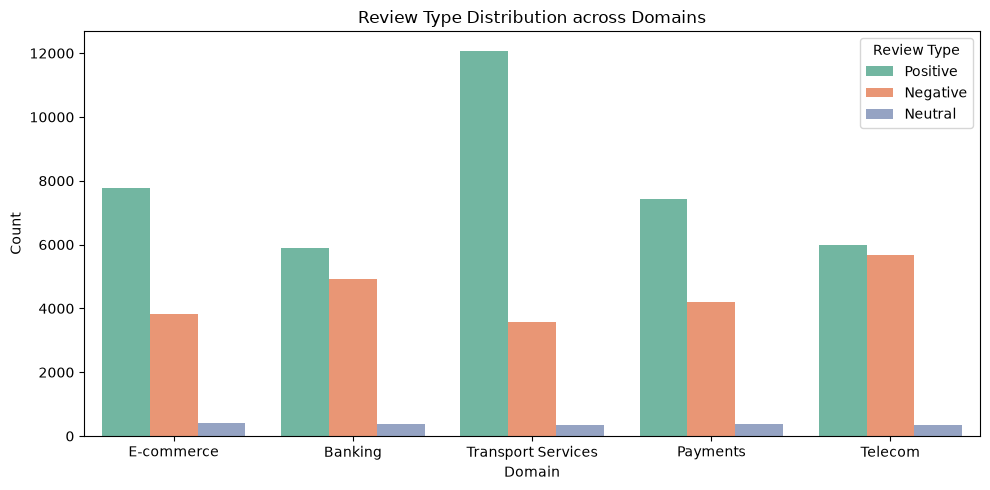

In [26]:
domain_summary = pd.crosstab(data['domain'], data['rating'], margins=True)
print("=== Rating Distribution Across Domains ===")
print(domain_summary)

plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='domain', hue='review_type', palette='Set2')
plt.title('Review Type Distribution across Domains')
plt.xlabel('Domain')
plt.ylabel('Count')
plt.legend(title='Review Type')
plt.tight_layout()
plt.show()

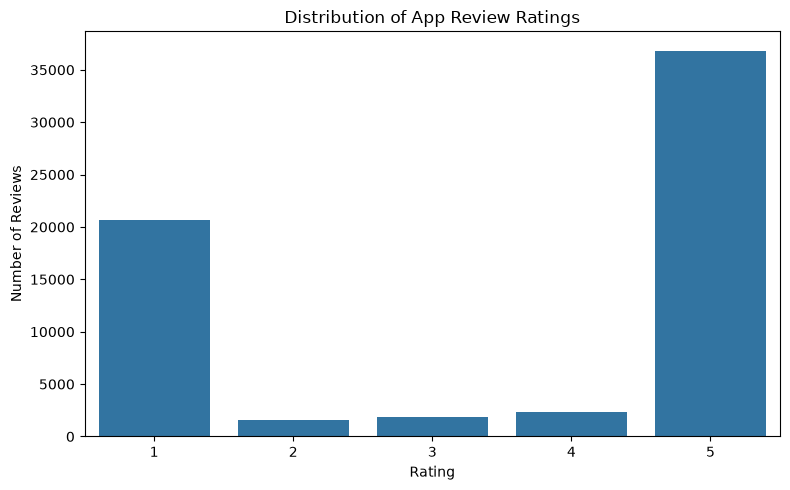

In [27]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=data,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of App Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [28]:
rating_by_app = pd.crosstab(
    data["app_name"],
    data["rating"]
)

rating_by_app.head()

rating,1,2,3,4,5
app_name,,,,,
Amazon,1609,95,119,137,2040
Banque Misr,1068,116,126,154,2536
CIB,1656,114,105,98,1235
Careem,1581,103,88,103,2124
DiDi,449,38,72,183,3258


In [29]:
rating_by_app["total_reviews"] = rating_by_app.sum(axis=1)

rating_by_app.sort_values(
    "total_reviews",
    ascending=False
).head(10)

rating,1,2,3,4,5,total_reviews
app_name,,,,,,
Amazon,1609,95,119,137,2040,4000
Banque Misr,1068,116,126,154,2536,4000
Etisalat Cash,1139,105,109,140,2507,4000
DiDi,449,38,72,183,3258,4000
Instapay,1087,91,96,138,2588,4000
Orange Egypt,776,123,130,156,2815,4000
Noon,903,85,127,199,2686,4000
NBE,1843,131,148,136,1742,4000
inDrive,820,57,84,127,2912,4000


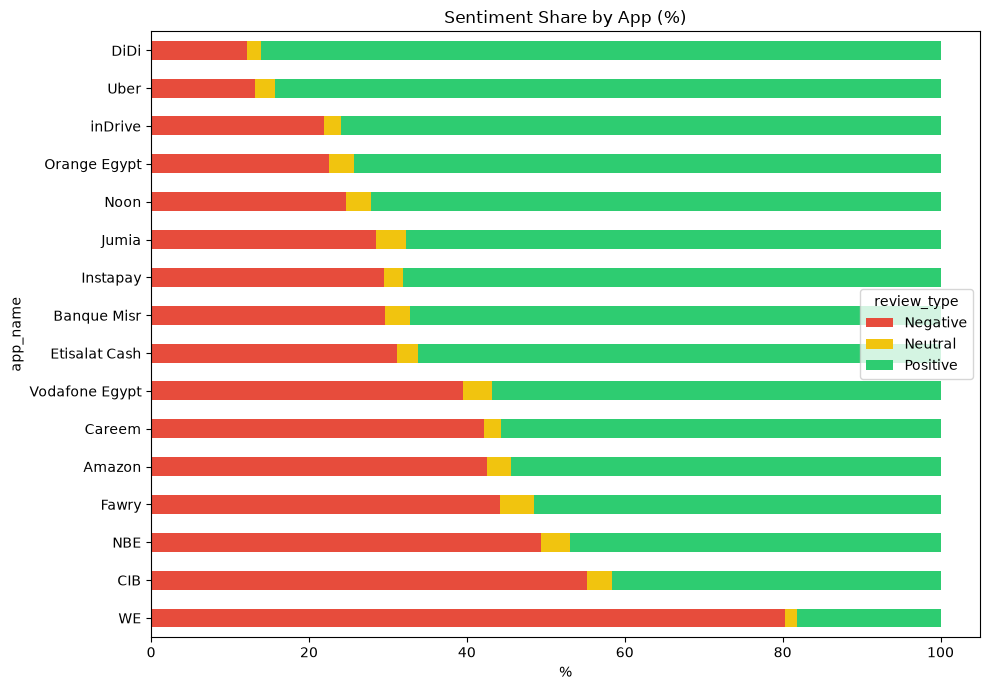

In [30]:
app_sent = pd.crosstab(data["app_name"], data["review_type"], normalize="index") * 100
app_sent = app_sent.sort_values("Negative", ascending=False)
app_sent.plot(kind="barh", stacked=True, figsize=(10, 7), color=["#e74c3c", "#f1c40f", "#2ecc71"])
plt.title("Sentiment Share by App (%)"); plt.xlabel("%"); plt.tight_layout(); plt.show()

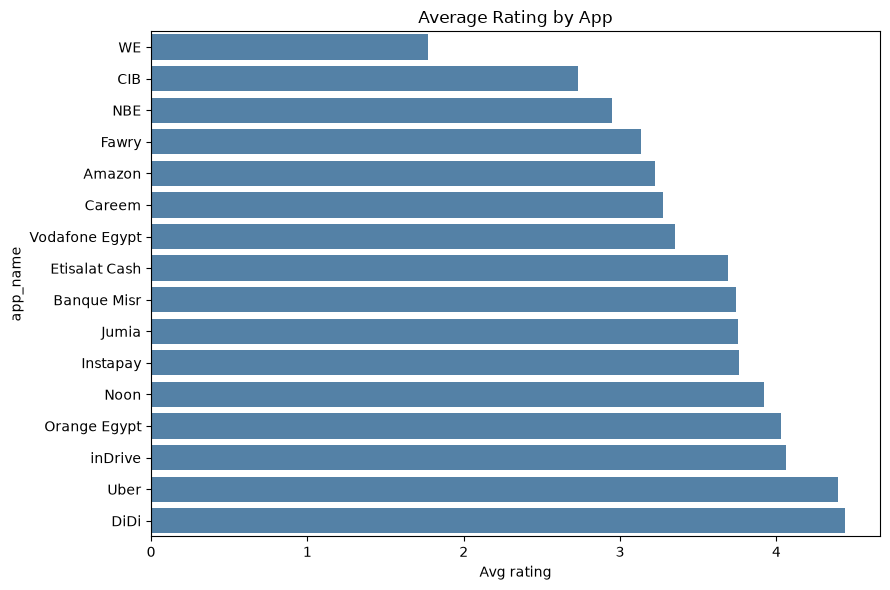

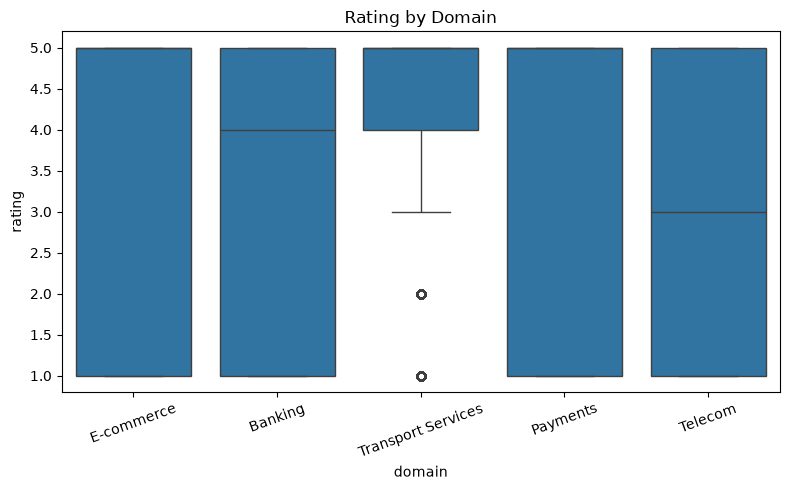

                    mean  median  count
domain                                 
Banking             3.17     4.0  11208
E-commerce          3.63     5.0  11999
Payments            3.53     5.0  11999
Telecom             3.05     3.0  12000
Transport Services  4.04     5.0  15998


In [31]:
avg_app = data.groupby("app_name")["rating"].agg(["mean", "count"]).sort_values("mean")
plt.figure(figsize=(9, 6)); sns.barplot(x=avg_app["mean"], y=avg_app.index, color="steelblue")
plt.title("Average Rating by App"); plt.xlabel("Avg rating"); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="domain", y="rating"); plt.xticks(rotation=20)
plt.title("Rating by Domain"); plt.tight_layout(); plt.show()
print(data.groupby("domain")["rating"].agg(["mean", "median", "count"]).round(2))

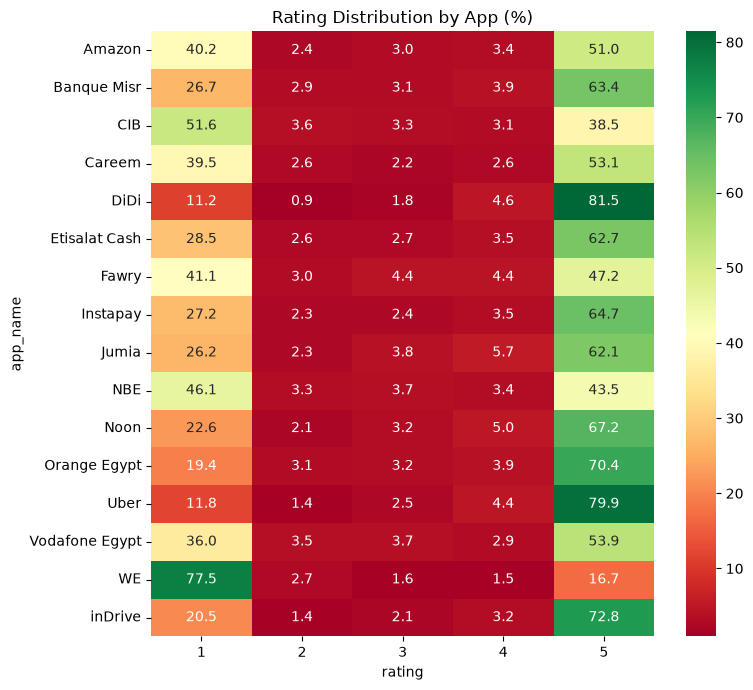

In [32]:
hm = pd.crosstab(data["app_name"], data["rating"], normalize="index") * 100
plt.figure(figsize=(8, 7)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="RdYlGn")
plt.title("Rating Distribution by App (%)"); plt.tight_layout(); plt.show()

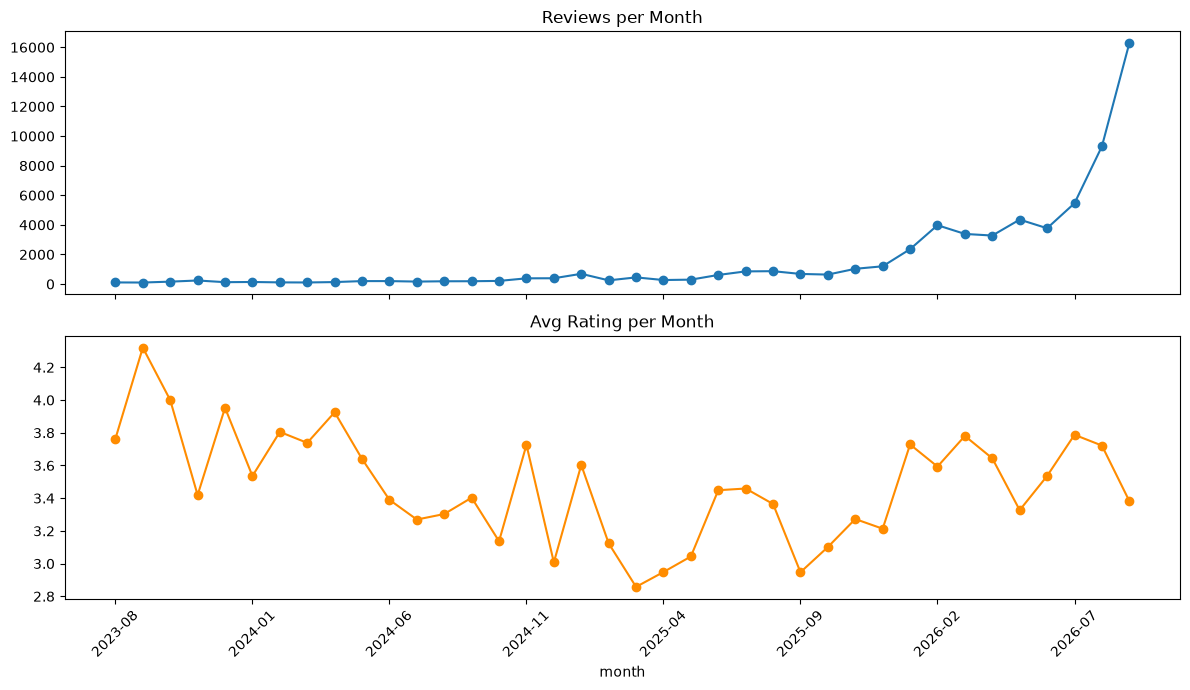

In [33]:
monthly = data.groupby("month").agg(reviews=("rating", "size"), avg_rating=("rating", "mean"))
monthly = monthly[monthly["reviews"] >= 30]
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
monthly["reviews"].plot(ax=ax[0], marker="o"); ax[0].set_title("Reviews per Month")
monthly["avg_rating"].plot(ax=ax[1], marker="o", color="darkorange"); ax[1].set_title("Avg Rating per Month")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

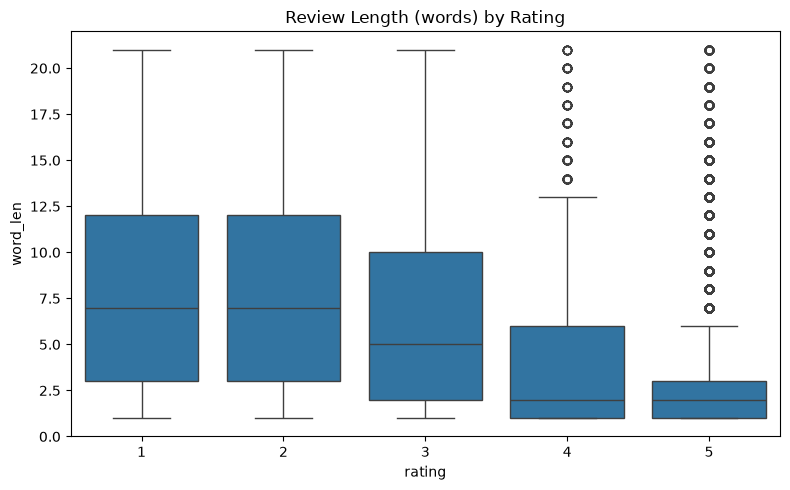

review_type
Negative    14.83
Neutral     11.37
Positive     3.84
Name: word_len, dtype: float64


In [34]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data[data["word_len"] <= upper], x="rating", y="word_len")
plt.title("Review Length (words) by Rating"); plt.tight_layout(); plt.show()
print(data.groupby("review_type")["word_len"].mean().round(2))

In [35]:
print((pd.crosstab(data["app_name"], data["script"], normalize="index") * 100).round(1))

script          arabic  latin  other/none
app_name                                 
Amazon            93.8    4.4         1.8
Banque Misr       95.5    3.4         1.1
CIB               95.0    4.1         1.0
Careem            95.6    2.8         1.7
DiDi              96.9    2.0         1.2
Etisalat Cash     96.9    1.8         1.4
Fawry             97.1    1.9         1.0
Instapay          96.4    2.6         1.0
Jumia             91.5    6.0         2.5
NBE               96.4    2.8         0.8
Noon              95.4    2.8         1.8
Orange Egypt      95.8    2.0         2.3
Uber              94.9    3.2         1.9
Vodafone Egypt    96.7    1.7         1.6
WE                96.9    2.0         1.1
inDrive           95.4    2.6         2.0


In [36]:
from collections import Counter
stop = set("في من على الى إلى عن مع ما لا و يا ده دي هو هي انا أنا كل لما اللي ان أن او أو the a to and is it i of for in this app".split())
def top_words(series, n=15):
    c = Counter(w for t in series for w in t.split() if len(w) > 2 and w not in stop)
    return pd.DataFrame(c.most_common(n), columns=["word", "count"])
for s in ["Negative", "Positive"]:
    print("\n==", s); print(top_words(data.loc[data["review_type"] == s, "normalized_text"]))


== Negative
        word  count
0    التطبيق   5926
1        جدا   4826
2      تطبيق   3613
3        علي   3392
4        ولا   2322
5        بعد   2046
6       خدمه   1887
7   البرنامج   1731
8        غير   1706
9       يعمل   1684
10     تحديث   1636
11   التحديث   1617
12      يفتح   1496
13      شركه   1465
14       مره   1362

== Positive
       word  count
0     ممتاز  10389
1       جدا   8315
2      جميل   3154
3       جيد   3124
4     تطبيق   3117
5      رائع   2438
6    ممتازه   2425
7   التطبيق   1641
8      شكرا   1482
9    برنامج   1231
10      علي   1184
11     تمام    943
12      حلو    854
13     خدمه    811
14     افضل    784


In [37]:
print(data["review_type"].value_counts(normalize=True).round(3))
print(data[["rating", "char_len", "word_len"]].corr(method="spearman").round(3))

review_type
Positive    0.620
Negative    0.351
Neutral     0.029
Name: proportion, dtype: float64
          rating  char_len  word_len
rating     1.000    -0.538    -0.563
char_len  -0.538     1.000     0.980
word_len  -0.563     0.980     1.000


In [38]:
print("Dataset shape:", data.shape)
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate review IDs:", data["review_id"].duplicated().sum())
print("Missing values:\n", data.isna().sum())
print("Ratings:", sorted(data["rating"].dropna().unique()))
print("Review labels:\n", data["review_type"].value_counts(dropna=False))

Dataset shape: (63204, 16)
Duplicate rows: 0
Duplicate review IDs: 0
Missing values:
 review_id          0
app_name           0
domain             0
rating             0
date               0
review_text        0
review_type        0
normalized_text    0
is_franco          0
script             0
is_franco_new      0
char_len           0
word_len           0
year               0
month              0
year_month         0
dtype: int64
Ratings: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Review labels:
 review_type
Positive    39158
Negative    22208
Neutral      1838
Name: count, dtype: int64


In [39]:
print(f"Rows: {len(data):,} | Columns: {data.shape[1]}")
print("\nReview-label distribution (%):")
display((data["review_type"].value_counts(normalize=True, dropna=False) * 100).round(2))
print("\nApp summary:")
display(data.groupby("app_name").agg(
    review_count=("review_id", "count"),
    average_rating=("rating", "mean")
).sort_values("review_count", ascending=False).round(2))

Rows: 63,204 | Columns: 16

Review-label distribution (%):


review_type
Positive    61.95
Negative    35.14
Neutral      2.91
Name: proportion, dtype: float64


App summary:


,review_count,average_rating
app_name,,
Amazon,4000,3.23
Banque Misr,4000,3.74
Etisalat Cash,4000,3.69
DiDi,4000,4.44
Instapay,4000,3.76
Orange Egypt,4000,4.03
Noon,4000,3.92
NBE,4000,2.95
inDrive,4000,4.06


In [40]:
data.to_csv("cleaned_app_reviews.csv", index=False)